# Cloud-masking a whole Sentinel-2 tile

A Sentinel-2 tile is 10980 x 10980 px, and a model trained on 1000 px patches won't take that in
one forward pass. This notebook gives ManyPred a whole tile and a real model, then measures what
the tiling settings change: how much overlap removes the seams, what skipping nodata saves, and
whether the result matches the library this code came from.

The model is [OmniCloudMask](https://github.com/DPIRD-DMA/OmniCloudMask) (OCM), a released
ensemble of two networks that labels each pixel clear, thick cloud, thin cloud or shadow. ManyPred
is OCM's inference engine pulled out into its own library, so this is its home ground. The
image is from the Kimberley in Western Australia, 17 January 2023: scattered wet-season cloud,
with a wedge of the tile outside the satellite's swath.

It downloads about 500 MB of imagery, plus the model's weights the first time. It takes a couple of
minutes on a GPU, and the saved timings are from an RTX 4090 that another process was also using.
A CPU can run it, but much more slowly.

You need `pip install "manypred[geo]" omnicloudmask matplotlib`.

In [1]:
import os
from pathlib import Path
from time import perf_counter
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import rasterio
import torch
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
from omnicloudmask import predict_from_array
from omnicloudmask.download_models import get_models
from omnicloudmask.model_utils import load_model_from_weights

from manypred import predict_array, predict_files
from manypred.geo import stack_rasters
from manypred.windows import plan_windows

DATA = Path(os.environ.get("MANYPRED_DATA", "data"))  # downloads go here
SMOKE = os.environ.get("MANYPRED_NOTEBOOK_SMOKE") == "1"  # the test suite: 160 m pixels, one model
RESOLUTION, PATCH, OVERLAP, BATCH = (160, 256, 64, 2) if SMOKE else (10, 1000, 300, 4)
OVERLAPS = (0, 16, 64, 128) if SMOKE else (0, 100, 300, 500)
device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

## Get the scene

OCM reads red, green and near infrared. Sentinel-2 has two of those at 10 m and the third
(band B8A) at 20 m. `stack_rasters` puts files covering one extent onto a single grid and returns
the array with a rasterio profile, so the outputs can be georeferenced later.

In [2]:
BUCKET = "https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs"
SCENE = "S2A_51KYV_20230117_0_L2A"
BANDS = ("B04", "B03", "B8A")  # red, green, near infrared


def band_path(scene, band):
    url = f"{BUCKET}/51/K/YV/2023/1/{scene}/{band}.tif"
    if SMOKE:  # read the file's overviews over the network instead of downloading it
        return url
    path = DATA / "s2" / scene / f"{band}.tif"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


paths = [band_path(SCENE, band) for band in BANDS]
scene, profile = stack_rasters(paths, resolution=RESOLUTION)
missing = (scene == 0).all(0)
print(f"{scene.shape}, {scene.dtype}, {scene.nbytes / 1e9:.2f} GB, {missing.mean():.1%} nodata")

(3, 10980, 10980), uint16, 0.72 GB, 14.9% nodata


## Where the patches go

Before running anything, here is what ManyPred plans for this scene. It lays 1000 px patches on a
grid with 300 px overlap, drops the patches that are entirely nodata, and shifts patches with a
nodata edge inward, so each one sees as much real image as it can.

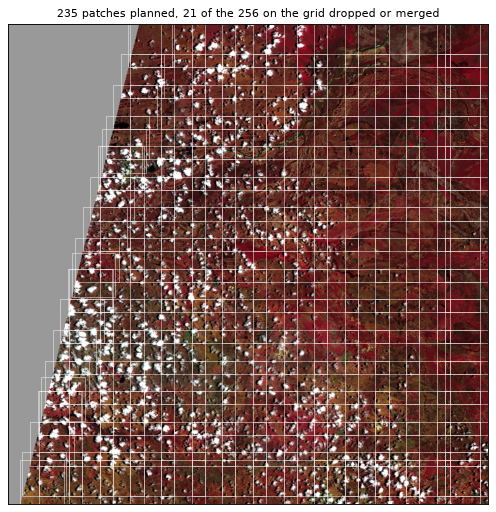

In [3]:
EMPTY = "#9a9a9a"


def false_colour(array, step=1):
    """NIR, red, green, stretched between 2nd and 98th percentiles of the valid pixels."""
    rgb = array[[2, 0, 1], ::step, ::step].transpose(1, 2, 0).astype(np.float32)
    valid = (rgb > 0).any(-1)
    if not valid.any():
        return np.full((*rgb.shape[:2], 3), 0.6)
    low, high = np.percentile(rgb[valid], (2, 98), axis=0)
    out = np.clip((rgb - low) / np.maximum(high - low, 1), 0, 1)
    out[~valid] = 0.6
    return out


height, width = missing.shape
planned = plan_windows(missing, PATCH, OVERLAP)
plain = plan_windows(np.zeros_like(missing), PATCH, OVERLAP)
step = max(1, height // 800)
overview = false_colour(scene, step)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(overview, extent=(0, width, height, 0))
for top, bottom, left, right in planned:
    ax.add_patch(
        Rectangle(
            (left, top), right - left, bottom - top, fill=False, ec="white", lw=0.5, alpha=0.8
        )
    )
ax.set(
    xticks=[],
    yticks=[],
    title=f"{len(planned)} patches planned, "
    f"{len(plain) - len(planned)} of the {len(plain)} on the grid dropped or merged",
)
fig.tight_layout()

## Predict

OCM's settings map onto one call. A list of models is an ensemble, and ManyPred averages their
raw outputs. `normalize` is a per-patch z-score, as OCM trained with. `nodata=0` marks missing
pixels, and `activation="softmax"` means probabilities get blended, not logits.

In [4]:
models = [
    load_model_from_weights(
        m["timm_model_name"], m["Path"], m["model_library"], torch.device(device)
    )
    for m in get_models()[: 1 if SMOKE else None]
]
common = {"normalize": {"type": "zscore", "scope": "tile"}, "batch_size": BATCH, "progress": False}


def timed(**kwargs):
    start = perf_counter()
    result = predict_array(models, scene, **common, **kwargs)
    return result, perf_counter() - start


probs, seconds = timed(
    patch_size=PATCH, overlap=OVERLAP, nodata=0, activation="softmax", output="probs"
)
print(f"{probs.shape} {probs.dtype} in {seconds:.1f} s on {device}")

CLASSES = ("clear", "thick cloud", "thin cloud", "shadow")
CLASS_COLOURS = ["#e8e4d8", "#1f6fb4", "#3fa7e8", "#d9480f", EMPTY]
classes = np.where(missing, 4, np.nan_to_num(probs).argmax(0)).astype(np.uint8)
for i, name in enumerate(CLASSES):
    print(f"{name:12} {(classes[~missing] == i).mean():6.1%}")

(4, 10980, 10980) float32 in 6.7 s on cuda


clear         68.0%
thick cloud   22.8%


thin cloud     0.1%
shadow         9.1%


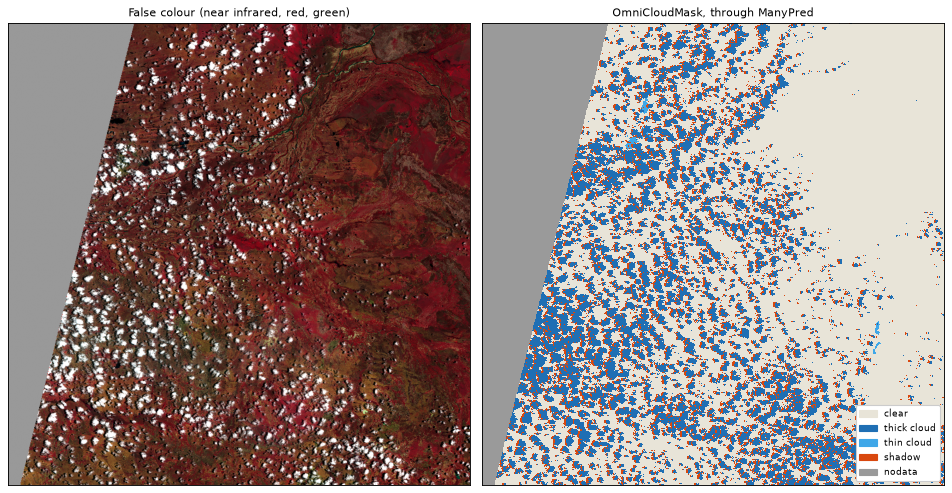

In [5]:
def show_classes(ax, array):
    ax.imshow(array, cmap=ListedColormap(CLASS_COLOURS), vmin=0, vmax=4, interpolation="nearest")


fig, axes = plt.subplots(1, 2, figsize=(12, 6.3))
axes[0].imshow(overview)
show_classes(axes[1], classes[::step, ::step])
axes[0].set_title("False colour (near infrared, red, green)")
axes[1].set_title("OmniCloudMask, through ManyPred")
for ax in axes:
    ax.set(xticks=[], yticks=[])
handles = [
    Patch(color=c, label=n) for c, n in zip(CLASS_COLOURS, (*CLASSES, "nodata"), strict=True)
]
axes[1].legend(handles=handles, loc="lower right", fontsize=8, framealpha=1)
fig.tight_layout()

## What overlap buys

A model sees less context near a patch's edge and predicts worse there. Without overlap those
edges meet, and the mosaic shows the patch grid. With overlap, each patch's weight fades toward
its edge, so the centre of a neighbouring patch takes over.

Here we run the tile at four overlaps and measure the seam directly. A seam is a row or column
where the probability jumps far more than it does on its neighbours, so the score is the biggest
jump between adjacent lines divided by the typical jump. The image has a floor of its own, because
some line in any tile crosses a lot of cloud edge. Alongside it is the share of pixels whose class
differs from the largest overlap.

overlap   0:   2.7 s, seam score   9.1, 0.59% of classes differ from overlap 500


overlap 100:   3.5 s, seam score   3.6, 0.54% of classes differ from overlap 500


overlap 300:   5.4 s, seam score   3.6, 0.44% of classes differ from overlap 500


overlap 500:   8.0 s, seam score   3.6, 0.00% of classes differ from overlap 500


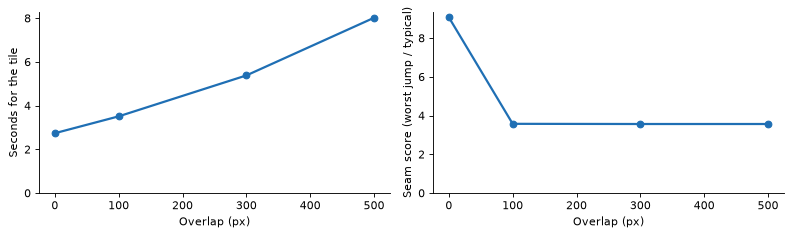

In [6]:
sweep = {}
for overlap in OVERLAPS:
    result, took = timed(
        patch_size=PATCH, overlap=overlap, nodata=0, activation="softmax", output="probs"
    )
    cloud = np.nan_to_num(result[1] + result[2]).astype(np.float32)
    sweep[overlap] = {
        "cloud": cloud,
        "classes": np.nan_to_num(result).argmax(0).astype(np.uint8),
        "seconds": took,
    }
    del result


def seam_score(cloud):
    """The worst row or column's mean jump, relative to the typical one, on valid pixels."""
    scores = []
    for axis in (0, 1):
        jump = np.abs(np.diff(cloud, axis=axis))
        keep = ~(
            np.take(missing, range(1, height if axis == 0 else width), axis=axis)
            | np.take(missing, range(0, (height if axis == 0 else width) - 1), axis=axis)
        )
        other = 1 - axis
        line = (jump * keep).sum(other) / np.maximum(keep.sum(other), 1)
        scores.append(line.max() / np.median(line))
    return max(scores)


reference = sweep[OVERLAPS[-1]]["classes"]
for overlap, run in sweep.items():
    run["changed"] = (run["classes"] != reference)[~missing].mean()
    run["seam"] = seam_score(run["cloud"])
    print(
        f"overlap {overlap:3}: {run['seconds']:5.1f} s, seam score {run['seam']:5.1f}, "
        f"{run['changed']:.2%} of classes differ from overlap {OVERLAPS[-1]}"
    )

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)
axes[0].plot(OVERLAPS, [sweep[o]["seconds"] for o in OVERLAPS], marker="o", color="#1f6fb4", lw=2)
axes[1].plot(OVERLAPS, [sweep[o]["seam"] for o in OVERLAPS], marker="o", color="#1f6fb4", lw=2)
axes[0].set(ylabel="Seconds for the tile", xlabel="Overlap (px)", ylim=(0, None))
axes[1].set(ylabel="Seam score (worst jump / typical)", xlabel="Overlap (px)", ylim=(0, None))
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

Any overlap removes the spike in the seam score, and past that the score stays at the image's own
floor. The class share barely moves, because a seam is local. It does little to a tile's average,
but anyone looking at the map will see it, and an outline traced from it will follow the patch
grid. OCM's default of 300 px costs about twice the time of no overlap on this tile.

Here is the worst patch corner in the overlap 0 run, where four patches meet in the middle of each
panel.

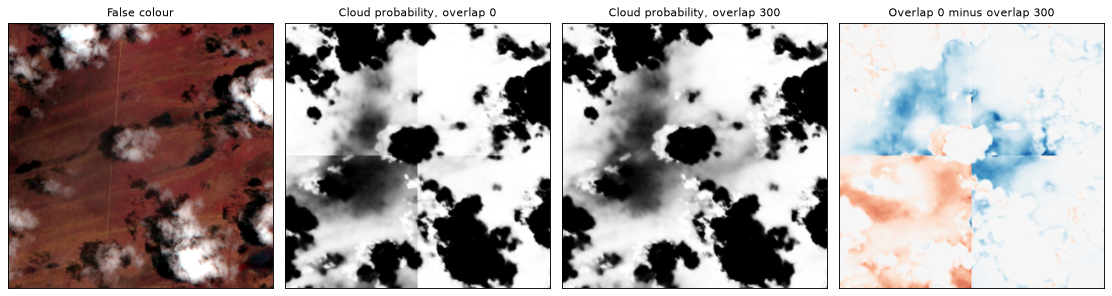

In [7]:
stride = PATCH  # overlap 0: patches meet at multiples of the patch size
half = PATCH // 3
changed = sweep[0]["classes"] != reference
corners = [
    (r, c)
    for r in range(stride, height - half, stride)
    for c in range(stride, width - half, stride)
]
worst = max(
    corners,
    key=lambda rc: (
        changed[rc[0] - half : rc[0] + half, rc[1] - half : rc[1] + half].sum()
        * (not missing[rc[0] - half : rc[0] + half, rc[1] - half : rc[1] + half].any())
    ),
)
crop = (slice(worst[0] - half, worst[0] + half), slice(worst[1] - half, worst[1] + half))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.7))
axes[0].imshow(false_colour(scene[(slice(None), *crop)]))
axes[0].set_title("False colour")
for ax, overlap in zip(axes[1:3], (0, OVERLAP), strict=True):
    ax.imshow(sweep[overlap]["cloud"][crop], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"Cloud probability, overlap {overlap}")
difference = sweep[0]["cloud"][crop] - sweep[OVERLAP]["cloud"][crop]
axes[3].imshow(difference, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[3].set_title(f"Overlap 0 minus overlap {OVERLAP}")
for ax in axes:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

## Nodata: skipped, shifted and masked

Passing `nodata=0` does three jobs. Patches that are entirely nodata never reach the GPU. Patches
that are partly nodata move inward, so the model sees more real image. And the final output is
masked wherever every band was missing, whatever the model made of it. This tile is only 15%
nodata, so the time saved is small. A tile that is half swath edge saves more.

In [8]:
runs = {
    "nodata=0": {"nodata": 0},
    "nodata=0, shift_patches=False": {"nodata": 0, "shift_patches": False},
    "nodata=None": {"nodata": None},
}
masks = {}
for label, kwargs in runs.items():
    masks[label], took = timed(patch_size=PATCH, overlap=OVERLAP, output="argmax", **kwargs)
    masks[label] = masks[label][0]
    changed = (masks[label] != masks["nodata=0"])[~missing].mean()
    print(f"{label:31} {took:6.1f} s, {changed:.3%} of valid pixels unlike nodata=0")
print("patches: planned with nodata", len(planned), "| without", len(plain))

nodata=0                           5.0 s, 0.000% of valid pixels unlike nodata=0


nodata=0, shift_patches=False      4.8 s, 0.046% of valid pixels unlike nodata=0


nodata=None                        4.7 s, 0.126% of valid pixels unlike nodata=0
patches: planned with nodata 235 | without 256


## Same answer as OmniCloudMask?

ManyPred's test suite checks it against golden files from OCM. Here is the same check on a
real tile, with OCM's own settings: float32, and patch shrinking over large nodata areas. The
classes can differ only where a pixel's top two classes are almost tied, because OCM normalises
patches with numpy and ManyPred with torch.

In [9]:
for _ in range(2):  # the second pass of each is the timing we keep: nothing left to warm up
    ocm_start = perf_counter()
    ocm = predict_from_array(
        scene,
        patch_size=PATCH,
        patch_overlap=OVERLAP,
        batch_size=BATCH,
        custom_models=models,
        inference_dtype="float32",
    )
    ocm_seconds = perf_counter() - ocm_start
    ours, ours_seconds = timed(
        patch_size=PATCH,
        overlap=OVERLAP,
        nodata=0,
        dtype="float32",
        adapt_patch_size=True,
        output="argmax",
    )
print(f"OCM {ocm_seconds:.1f} s, ManyPred {ours_seconds:.1f} s")
print(f"{(ocm == ours).mean():.5%} of pixels match, {(ocm != ours).sum()} of {ocm.size} differ")

OCM 4.8 s, ManyPred 4.8 s
99.99963% of pixels match, 446 of 120560400 differ


## From files to files

For real work you rarely want the array. `predict_files` loads on one background thread, writes on
another and keeps the GPU busy in between. The default writer puts the classes in a GeoTIFF on the
source grid, with nodata in the mask band. `overwrite=False` skips any scene already finished, so
a stopped job can pick up where it left off.

In [10]:
def load(item):
    return stack_rasters([band_path(item, band) for band in BANDS], resolution=RESOLUTION)


[written] = predict_files(
    models,
    [SCENE],
    load_func=load,
    output_dir=DATA / "cloud_masks",
    patch_size=PATCH,
    overlap=OVERLAP,
    nodata=0,
    output="argmax",
    overwrite=True,
    **common,
)
with rasterio.open(written) as src:
    print(
        f"{written.name}: {src.shape}, {src.dtypes[0]}, {src.crs}, "
        f"{written.stat().st_size / 1e6:.0f} MB"
    )
    print(
        "valid pixels in the mask band:", f"{(src.dataset_mask()[::step, ::step] > 0).mean():.1%}"
    )

S2A_51KYV_20230117_0_L2A_pred.tif: (10980, 10980), uint8, EPSG:32751, 4 MB
valid pixels in the mask band: 85.0%


## Where to go next

* Train your own model and let the file carry its settings, in
  [the flood notebook](02_flood_scene.ipynb).
* Feed several resolutions and read several kinds of output, in
  [the next one](03_two_grids_many_heads.ipynb).
* Turn saved rasters into polygons without loading a scene, in
  [the block notebook](04_blocks_to_polygons.ipynb).